# Sumativa 2: Simulación y Remuestreo
**Magíster en Ciencia de Datos e Inteligencia Artificial - UNAB**

**Integrantes:** Verónica Durán, Raúl Moya, Daniela Rojas, Manuel Sánchez  
**Grupo:** 2  
**Curso:** MCDI501 - Estadística Computacional para la Toma de Decisiones  
**Dataset:** Online Shoppers Purchasing Intention  
**Fase 3:** Simulación, remuestreo y evaluación de robustez

## Objetivo
Validar y profundizar los resultados de la Sumativa 1 mediante bootstrap, permutación, evaluación de estabilidad de correlaciones, simulación Monte Carlo y análisis de robustez.

> **Pregunta del proyecto:** ¿Qué características del comportamiento de navegación de los usuarios se relacionan con la probabilidad de que una sesión de comercio electrónico termine en una compra?

Las conclusiones se interpretan como asociaciones estadísticas y no como relaciones causales.


## 1. Trazabilidad S1 → S2
La evaluación se construye explícitamente sobre S1:

| Resultado S1 | Referencia | Validación S2 |
|---|---:|---|
| Media ProductRelated_Duration | 1194,7462 | Bootstrap percentil + BCa |
| Media PageValues | 5,8893 | Bootstrap percentil + BCa |
| Media ExitRates | 0,0431 | Bootstrap percentil + BCa |
| PageValues según Revenue | Mann–Whitney U=17.166.757 | Permutación |
| BounceRates–ExitRates | r=0,913004 | Bootstrap |
| ProductRelated–ProductRelated_Duration | r=0,860927 | Bootstrap |
| Informational–Informational_Duration | r=0,618955 | Bootstrap |
| Administrative–Administrative_Duration | r=0,601583 | Bootstrap |
| Revenue=True | ≈15,47 % | Monte Carlo + sensibilidad |


In [1]:
# 2. Entorno y reproducibilidad
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
N_RESAMPLES = 10_000
ALPHA = 0.05
rng = np.random.default_rng(RANDOM_STATE)
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")
print("Entorno preparado.", "Semilla:", RANDOM_STATE)


Entorno preparado. Semilla: 42


### Reproducibilidad
Los métodos de simulación y remuestreo incorporan aleatoriedad. Se utiliza `np.random.default_rng(42)` para obtener resultados reproducibles. La semilla fija la secuencia pseudoaleatoria de esta ejecución, pero no elimina la naturaleza aleatoria del procedimiento.


In [2]:
# 3. Carga y control de continuidad con S1
rutas = [Path("data/raw/online_shoppers_intention.csv"),
         Path("../data/raw/online_shoppers_intention.csv")]
ruta = next((p for p in rutas if p.exists()), None)
if ruta is None:
    raise FileNotFoundError("No se encontró el CSV en data/raw.")

df = pd.read_csv(ruta)
if df["Revenue"].dtype == object:
    df["Revenue"] = df["Revenue"].astype(str).str.strip().str.lower().map({"true":True,"false":False})
if df["Revenue"].isna().any():
    raise ValueError("Revenue contiene valores no reconocidos.")
df["Revenue"] = df["Revenue"].astype(bool)

verificacion = pd.Series({
    "Sesiones": len(df),
    "Variables": df.shape[1],
    "Faltantes": int(df.isna().sum().sum()),
    "Filas con valores idénticos": int(df.duplicated().sum()),
    "Compras": int(df["Revenue"].sum()),
    "No compras": int((~df["Revenue"]).sum()),
    "Tasa de conversión": df["Revenue"].mean()
})
display(verificacion.to_frame("S2"))
assert df.shape == (12330,18)
assert df.isna().sum().sum() == 0


,S2
Sesiones,"12,330.000000"
Variables,18.000000
Faltantes,0.000000
Filas con valores idénticos,125.000000
Compras,"1,908.000000"
No compras,"10,422.000000"
Tasa de conversión,0.154745


Las filas con valores idénticos se documentan pero no se eliminan automáticamente: igualdad en los atributos observados no demuestra que correspondan a una misma sesión. Esta decisión conserva el criterio metodológico de S1.


In [3]:
# 4. Parámetros de referencia S1
variables_ic = ["ProductRelated_Duration","PageValues","ExitRates"]
ref_s1 = pd.DataFrame({
    "variable": variables_ic,
    "media_S1":[1194.7462,5.8893,0.0431],
    "clasico_inf":[1160.9649,5.5615,0.0422],
    "clasico_sup":[1228.5275,6.2170,0.0439]
})
ref_s1["media_recalculada"] = [df[v].mean() for v in variables_ic]
display(ref_s1)


,variable,media_S1,clasico_inf,clasico_sup,media_recalculada
0,ProductRelated_Duration,"1,194.746200","1,160.964900","1,228.527500","1,194.746220"
1,PageValues,5.889300,5.561500,6.217000,5.889258
2,ExitRates,0.043100,0.042200,0.043900,0.043073


## 5. Bootstrap no paramétrico: validación de IC
Para cada uno de los tres parámetros de S1 se realizan **10.000 remuestras con reemplazo**. Se calcula la media y se obtienen IC 95 % por método **percentil** y **BCa**. La comparación con el IC clásico permite evaluar sensibilidad a los supuestos del método original, especialmente ante asimetría y valores extremos.


,Variable,Media,Clásico inf,Clásico sup,Percentil inf,Percentil sup,BCa inf,BCa sup,SE bootstrap,Ancho clásico,Ancho percentil,Ancho BCa
0,ProductRelated_Duration,"1,194.746220","1,160.964900","1,228.527500","1,161.361347","1,229.231743","1,162.484876","1,230.951845",17.281662,67.562600,67.870396,68.466969
1,PageValues,5.889258,5.561500,6.217000,5.573059,6.222113,5.580391,6.234119,0.165938,0.655500,0.649053,0.653728
2,ExitRates,0.043073,0.042200,0.043900,0.042219,0.043940,0.042238,0.043959,0.000435,0.001700,0.001721,0.001720


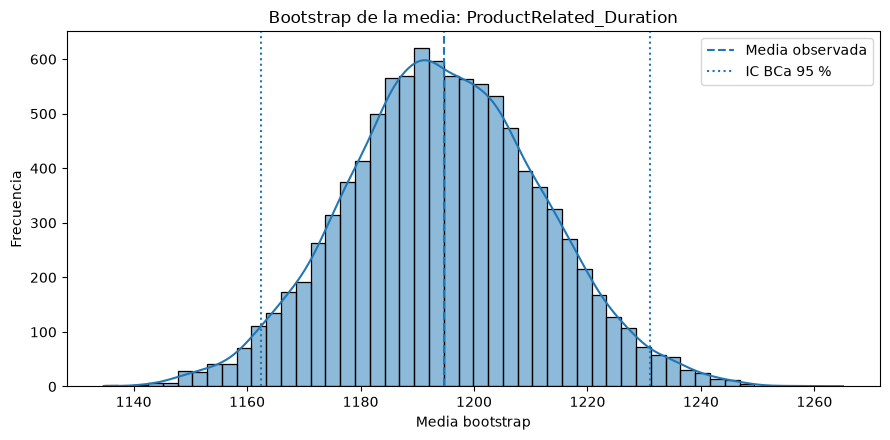

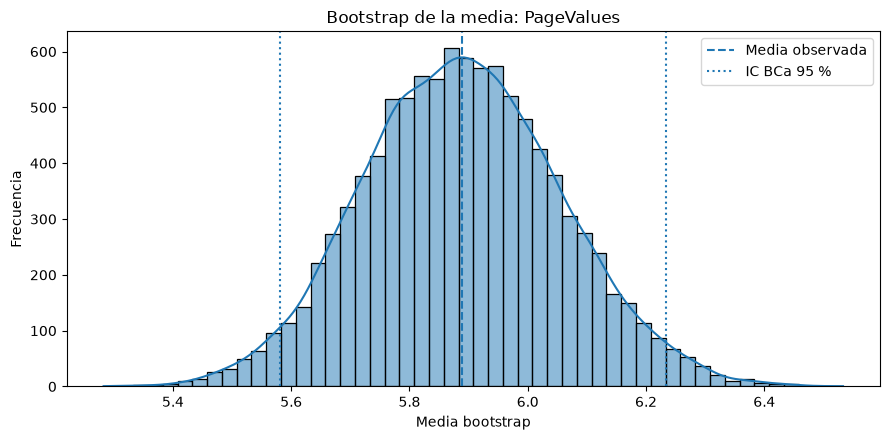

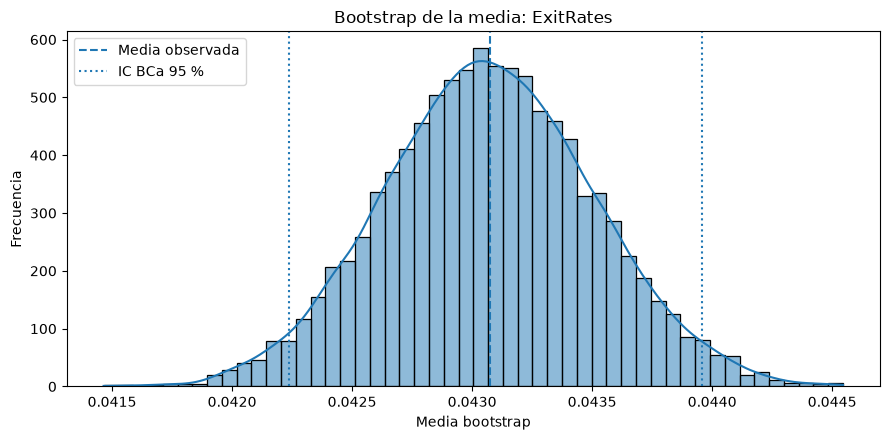

In [4]:
# 5.1 Bootstrap percentil y BCa
def bootstrap_media(x, seed):
    x = np.asarray(x, float)
    res = stats.bootstrap(
        (x,), np.mean, confidence_level=.95, n_resamples=N_RESAMPLES,
        method="BCa", random_state=np.random.default_rng(seed), batch=250
    )
    d = np.asarray(res.bootstrap_distribution)
    q = np.quantile(d,[.025,.975])
    return dict(media=x.mean(), se=d.std(ddof=1),
                pct_inf=q[0],pct_sup=q[1],
                bca_inf=res.confidence_interval.low,
                bca_sup=res.confidence_interval.high,dist=d)

boot = {}
filas = []
for i,v in enumerate(variables_ic):
    r = bootstrap_media(df[v], RANDOM_STATE+i)
    boot[v] = r
    s = ref_s1.loc[ref_s1.variable==v].iloc[0]
    filas.append([v,r["media"],s.clasico_inf,s.clasico_sup,
                  r["pct_inf"],r["pct_sup"],r["bca_inf"],r["bca_sup"],r["se"]])

tabla_boot = pd.DataFrame(filas,columns=[
    "Variable","Media","Clásico inf","Clásico sup","Percentil inf",
    "Percentil sup","BCa inf","BCa sup","SE bootstrap"])
tabla_boot["Ancho clásico"]=tabla_boot["Clásico sup"]-tabla_boot["Clásico inf"]
tabla_boot["Ancho percentil"]=tabla_boot["Percentil sup"]-tabla_boot["Percentil inf"]
tabla_boot["Ancho BCa"]=tabla_boot["BCa sup"]-tabla_boot["BCa inf"]
display(tabla_boot)

for v,r in boot.items():
    fig,ax=plt.subplots(figsize=(9,4.5))
    sns.histplot(r["dist"],bins=50,kde=True,ax=ax)
    ax.axvline(r["media"],ls="--",label="Media observada")
    ax.axvline(r["bca_inf"],ls=":",label="IC BCa 95 %"); ax.axvline(r["bca_sup"],ls=":")
    ax.set(title=f"Bootstrap de la media: {v}",xlabel="Media bootstrap",ylabel="Frecuencia")
    ax.legend(); plt.tight_layout(); plt.show()


### Interpretación del bootstrap
Se considerará mayor estabilidad cuando los IC clásico, percentil y BCa sean próximos en localización y amplitud. Diferencias apreciables, particularmente entre el clásico y BCa, señalarán sensibilidad a asimetría, sesgo o valores extremos. La evaluación no se limitará a comprobar superposición de intervalos.


## 6. Validación de hipótesis mediante permutación
En S1 `PageValues` se comparó según `Revenue` con Mann–Whitney. En S2 se aplica un test de permutación bilateral con **10.000 permutaciones**.

- **H₀:** bajo intercambiabilidad de las etiquetas de compra, no existe diferencia sistemática de `PageValues` entre grupos.
- **H₁:** la diferencia observada es incompatible con H₀.
- **α = 0,05.**

Se usa la **diferencia de medias** como estadístico de permutación por su interpretación directa en las unidades de `PageValues`. Se compara la decisión con Mann–Whitney, reconociendo que ambos procedimientos no prueban exactamente la misma hipótesis matemática.


Diferencia observada = 25.288520
p permutación = 9.999e-05
Referencia S1: Mann–Whitney U = 17,166,757; p < 1e-300


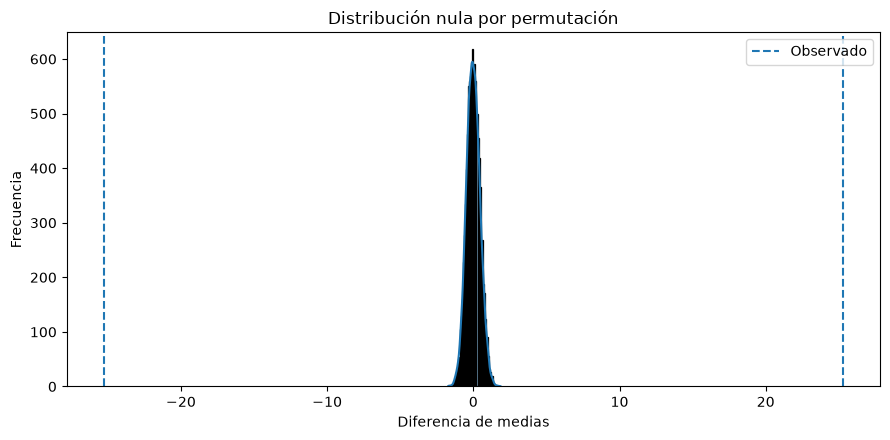

In [5]:
# 6.1 Permutación PageValues × Revenue
x = df["PageValues"].to_numpy(float)
g = df["Revenue"].to_numpy(bool)
n=len(x); n1=int(g.sum()); total=x.sum()
dif_obs=x[g].mean()-x[~g].mean()

gen=np.random.default_rng(RANDOM_STATE)
perm=np.empty(N_RESAMPLES)
for b in range(N_RESAMPLES):
    idx=gen.choice(n,size=n1,replace=False)
    s1=x[idx].sum()
    perm[b]=s1/n1-(total-s1)/(n-n1)

p_perm=(np.sum(np.abs(perm)>=abs(dif_obs))+1)/(N_RESAMPLES+1)
print(f"Diferencia observada = {dif_obs:.6f}")
print(f"p permutación = {p_perm:.6g}")
print("Referencia S1: Mann–Whitney U = 17,166,757; p < 1e-300")

fig,ax=plt.subplots(figsize=(9,4.5))
sns.histplot(perm,bins=50,kde=True,ax=ax)
ax.axvline(dif_obs,ls="--",label="Observado"); ax.axvline(-dif_obs,ls="--")
ax.set(title="Distribución nula por permutación",xlabel="Diferencia de medias",ylabel="Frecuencia")
ax.legend(); plt.tight_layout(); plt.show()


Con 10.000 permutaciones y corrección +1, el p-valor mínimo observable es aproximadamente `1/10.001`. Por ello, un valor cercano a ese límite expresa la resolución de la simulación y no debe equipararse numéricamente al p extremadamente pequeño de S1.


## 7. Estabilidad de correlaciones
Se evalúan cuatro correlaciones relevantes de S1 mediante 10.000 remuestras bootstrap de las filas. Se reporta IC percentil 95 %, amplitud e inclusión de cero. Un IC concentrado alrededor del valor observado y que no incluya cero aporta evidencia de estabilidad muestral.


,Variable 1,Variable 2,r,IC inf,IC sup,Ancho,Incluye 0
0,BounceRates,ExitRates,0.913004,0.906614,0.919058,0.012443,False
1,ProductRelated,ProductRelated_Duration,0.860927,0.827588,0.886628,0.059039,False
2,Informational,Informational_Duration,0.618955,0.588544,0.652060,0.063516,False
3,Administrative,Administrative_Duration,0.601583,0.575472,0.628174,0.052701,False


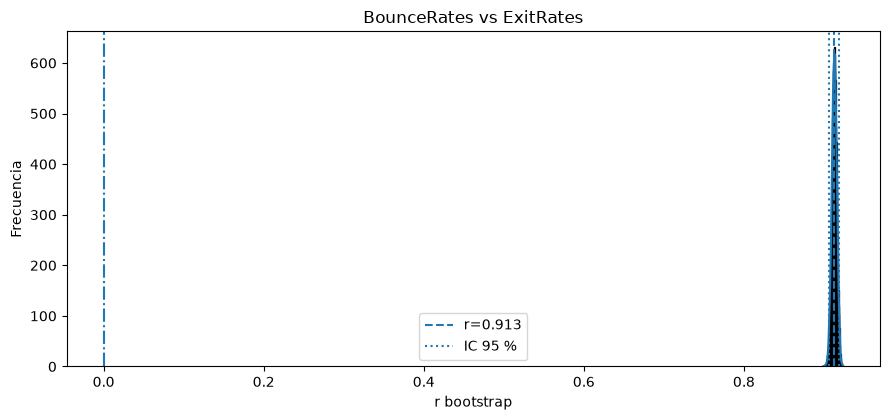

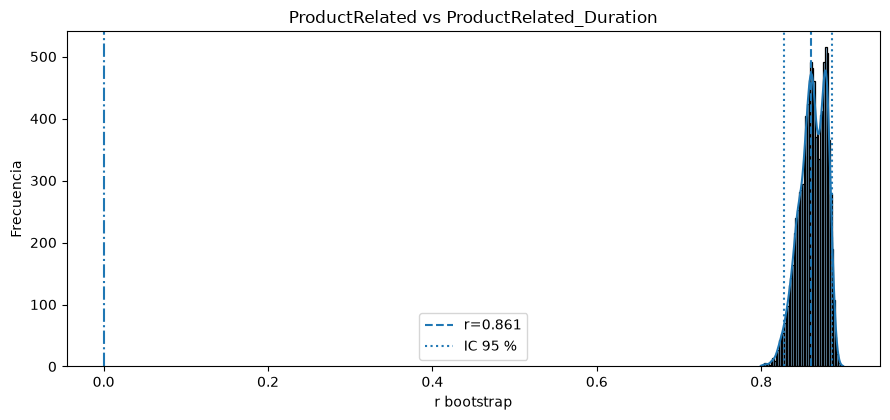

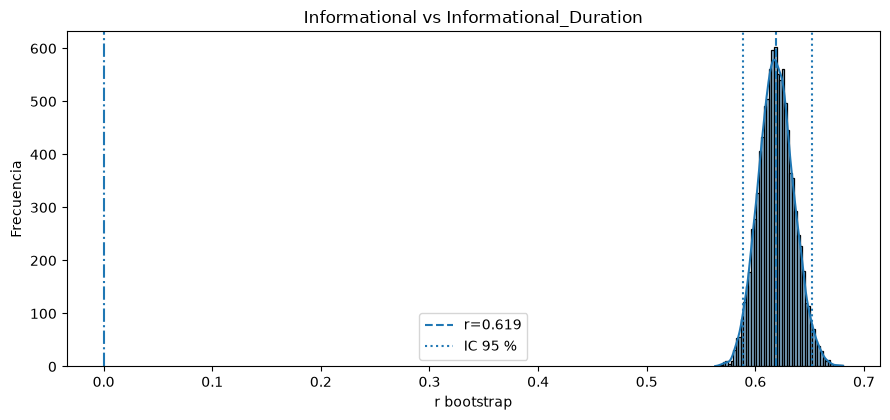

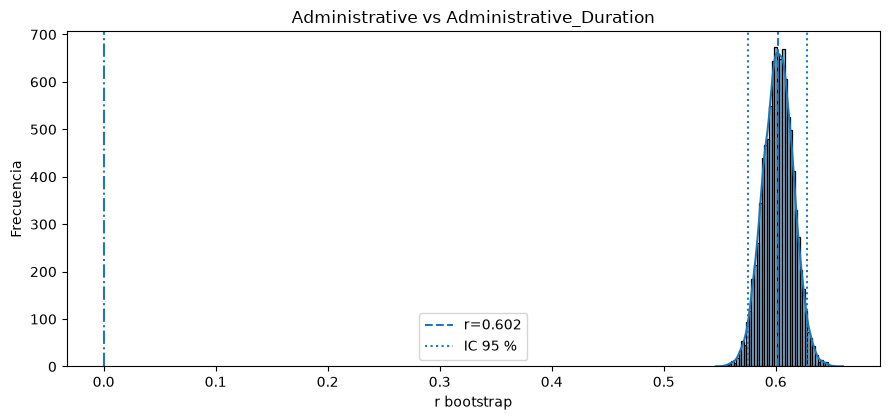

In [6]:
# 7.1 Bootstrap de correlaciones
pares=[
("BounceRates","ExitRates"),
("ProductRelated","ProductRelated_Duration"),
("Informational","Informational_Duration"),
("Administrative","Administrative_Duration")]

def boot_corr(x,y,seed):
    x=np.asarray(x,float); y=np.asarray(y,float); n=len(x)
    gen=np.random.default_rng(seed); d=np.empty(N_RESAMPLES); batch=250
    for ini in range(0,N_RESAMPLES,batch):
        m=min(batch,N_RESAMPLES-ini)
        idx=gen.integers(0,n,size=(m,n))
        xb=x[idx]; yb=y[idx]
        xc=xb-xb.mean(1,keepdims=True); yc=yb-yb.mean(1,keepdims=True)
        den=np.sqrt((xc**2).sum(1)*(yc**2).sum(1))
        d[ini:ini+m]=(xc*yc).sum(1)/den
    r=np.corrcoef(x,y)[0,1]; lo,hi=np.quantile(d,[.025,.975])
    return r,lo,hi,d

corr_dist={}; rows=[]
for i,(a,b) in enumerate(pares):
    r,lo,hi,d=boot_corr(df[a],df[b],RANDOM_STATE+100+i)
    corr_dist[(a,b)]=d
    rows.append([a,b,r,lo,hi,hi-lo,lo<=0<=hi])
tabla_corr=pd.DataFrame(rows,columns=["Variable 1","Variable 2","r","IC inf","IC sup","Ancho","Incluye 0"])
display(tabla_corr)

for (a,b),d in corr_dist.items():
    fig,ax=plt.subplots(figsize=(9,4.3))
    sns.histplot(d,bins=50,kde=True,ax=ax)
    lo,hi=np.quantile(d,[.025,.975]); r=np.corrcoef(df[a],df[b])[0,1]
    ax.axvline(r,ls="--",label=f"r={r:.3f}")
    ax.axvline(lo,ls=":",label="IC 95 %"); ax.axvline(hi,ls=":"); ax.axvline(0,ls="-.")
    ax.set(title=f"{a} vs {b}",xlabel="r bootstrap",ylabel="Frecuencia")
    ax.legend(); plt.tight_layout(); plt.show()


## 8. Simulación Monte Carlo
Se utiliza exclusivamente información estimada en S1. Sea `n=12.330` y `p̂` la proporción observada de sesiones con compra. En cada una de **10.000 iteraciones** se simula:

\[
X_i \sim Binomial(n,\hat p), \qquad \hat p_i=X_i/n
\]

El objetivo es propagar la incertidumbre aleatoria de la tasa de conversión bajo este escenario. No constituye un pronóstico causal de ventas futuras.


,Monte Carlo
p S1,0.154745
IC S1 inf,0.148361
IC S1 sup,0.161128
Media MC,0.154748
DE MC,0.003299
P2.5 MC,0.148337
P97.5 MC,0.161152


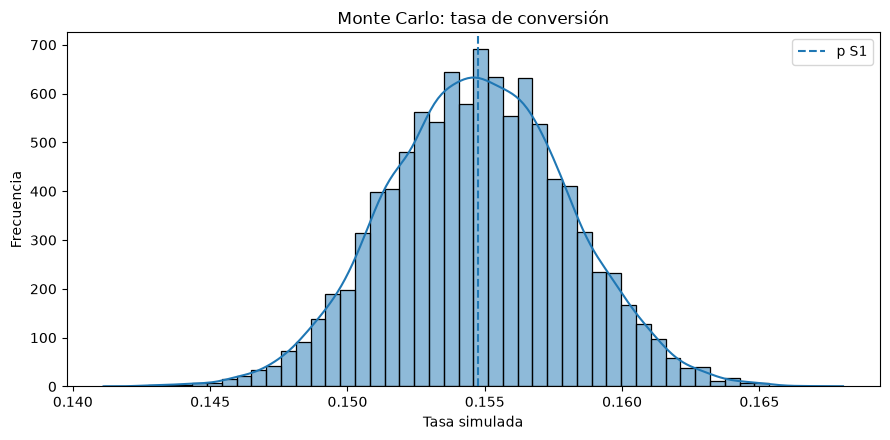

,Iteraciones,Media acumulada,Error absoluto
0,100,0.154277,0.000467
1,500,0.154602,0.000143
2,1000,0.154771,0.000027
3,2500,0.154842,0.000098
4,5000,0.154805,0.000061
5,10000,0.154748,0.000003


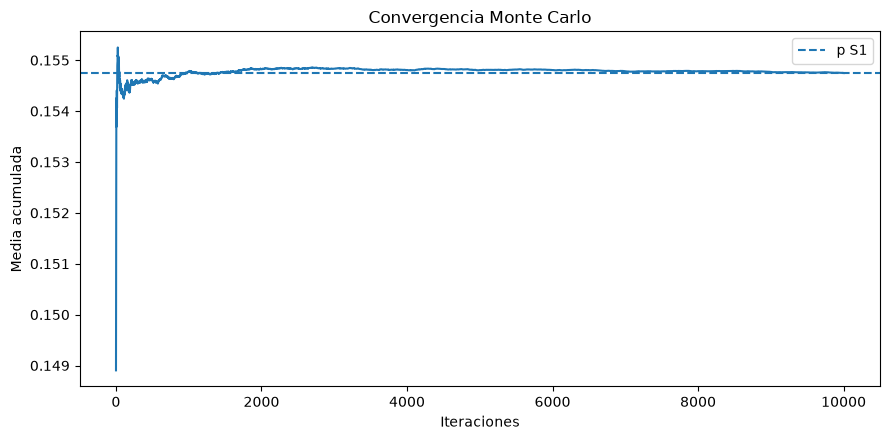

In [7]:
# 8.1 Monte Carlo y convergencia
n_ses=len(df); p=df["Revenue"].mean()
se=np.sqrt(p*(1-p)/n_ses); z=stats.norm.ppf(.975)
ic_prop=(p-z*se,p+z*se)

gen=np.random.default_rng(RANDOM_STATE)
compras=gen.binomial(n_ses,p,size=N_RESAMPLES)
tasas=compras/n_ses
res_mc=pd.Series({
"p S1":p,"IC S1 inf":ic_prop[0],"IC S1 sup":ic_prop[1],
"Media MC":tasas.mean(),"DE MC":tasas.std(ddof=1),
"P2.5 MC":np.quantile(tasas,.025),"P97.5 MC":np.quantile(tasas,.975)})
display(res_mc.to_frame("Monte Carlo"))

fig,ax=plt.subplots(figsize=(9,4.5))
sns.histplot(tasas,bins=50,kde=True,ax=ax); ax.axvline(p,ls="--",label="p S1")
ax.set(title="Monte Carlo: tasa de conversión",xlabel="Tasa simulada",ylabel="Frecuencia")
ax.legend(); plt.tight_layout(); plt.show()

ac=np.cumsum(tasas)/np.arange(1,N_RESAMPLES+1)
puntos=[100,500,1000,2500,5000,10000]
conv=pd.DataFrame({"Iteraciones":puntos,"Media acumulada":[ac[i-1] for i in puntos]})
conv["Error absoluto"]=abs(conv["Media acumulada"]-p)
display(conv)

fig,ax=plt.subplots(figsize=(9,4.5))
ax.plot(np.arange(1,N_RESAMPLES+1),ac); ax.axhline(p,ls="--",label="p S1")
ax.set(title="Convergencia Monte Carlo",xlabel="Iteraciones",ylabel="Media acumulada")
ax.legend(); plt.tight_layout(); plt.show()


## 9. Datos sintéticos y sensibilidad
Monte Carlo genera resultados sintéticos bajo un modelo probabilístico. Para evidenciar ID2.2 se crea además una muestra binaria sintética `Revenue` del mismo tamaño que S1. Para ID2.3 se evalúan tres escenarios usando exclusivamente parámetros derivados de S1: límite inferior del IC de la proporción, estimación puntual y límite superior.


,Fuente,n,Tasa compra
0,S1,12330,0.154745
1,Sintético,12330,0.151906


,Escenario,p entrada,Media,DE,P2.5,P97.5
0,IC inferior S1,0.148361,0.148350,0.003225,0.142011,0.154663
1,Estimación S1,0.154745,0.154672,0.003160,0.148500,0.160827
2,IC superior S1,0.161128,0.161074,0.003315,0.154420,0.167640


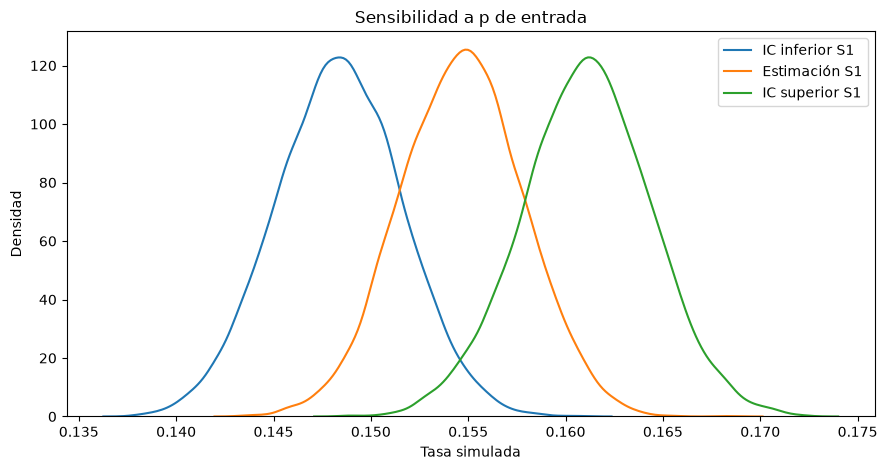

In [8]:
# 9.1 Datos sintéticos + sensibilidad
gen=np.random.default_rng(RANDOM_STATE)
rev_sint=gen.binomial(1,p,size=n_ses).astype(bool)
display(pd.DataFrame({
"Fuente":["S1","Sintético"],"n":[n_ses,n_ses],
"Tasa compra":[p,rev_sint.mean()]}))

esc={"IC inferior S1":ic_prop[0],"Estimación S1":p,"IC superior S1":ic_prop[1]}
sens=[]; sens_dist={}
for i,(nombre,pe) in enumerate(esc.items()):
    gen=np.random.default_rng(RANDOM_STATE+200+i)
    t=gen.binomial(n_ses,pe,size=N_RESAMPLES)/n_ses
    sens_dist[nombre]=t
    sens.append([nombre,pe,t.mean(),t.std(ddof=1),*np.quantile(t,[.025,.975])])
tabla_sens=pd.DataFrame(sens,columns=["Escenario","p entrada","Media","DE","P2.5","P97.5"])
display(tabla_sens)

fig,ax=plt.subplots(figsize=(9,4.8))
for nombre,t in sens_dist.items(): sns.kdeplot(t,label=nombre,ax=ax)
ax.set(title="Sensibilidad a p de entrada",xlabel="Tasa simulada",ylabel="Densidad")
ax.legend(); plt.tight_layout(); plt.show()


## 10. Robustez frente a outliers y observaciones influyentes
Se comparan media, mediana y media recortada 5 %, y se aplica jackknife a la media. Las cercas IQR se usan únicamente para **diagnóstico**; no se eliminan observaciones. El objetivo es medir cuánto cambia la conclusión ante colas y observaciones influyentes.


In [9]:
# 10.1 Sensibilidad a extremos + jackknife
vars_rob=["ProductRelated_Duration","PageValues","ExitRates"]
rob=[]; jack=[]
for v in vars_rob:
    x=df[v].to_numpy(float); media=x.mean(); med=np.median(x)
    trim=stats.trim_mean(x,.05)
    q1,q3=np.quantile(x,[.25,.75]); iqr=q3-q1
    ext=(x<q1-1.5*iqr)|(x>q3+1.5*iqr)
    rob.append([v,media,med,trim,100*(trim-media)/media,ext.sum(),100*ext.mean()])

    n=len(x); loo=(x.sum()-x)/(n-1); mj=loo.mean()
    sej=np.sqrt((n-1)/n*np.sum((loo-mj)**2))
    infl=np.abs(loo-media); k=np.argmax(infl)
    jack.append([v,media,mj,sej,infl[k],k,x[k]])

tabla_rob=pd.DataFrame(rob,columns=[
"Variable","Media","Mediana","Media recortada 5%","Cambio relativo %",
"N fuera cercas IQR","% fuera cercas IQR"])
tabla_jack=pd.DataFrame(jack,columns=[
"Variable","Media","Media jackknife","SE jackknife","Máx cambio leave-one-out",
"Índice más influyente","Valor más influyente"])
display(tabla_rob); display(tabla_jack)


,Variable,Media,Mediana,Media recortada 5%,Cambio relativo %,N fuera cercas IQR,% fuera cercas IQR
0,ProductRelated_Duration,"1,194.746220",598.936905,925.059132,-22.572751,961,7.793998
1,PageValues,5.889258,0.000000,2.647401,-55.046957,2730,22.141119
2,ExitRates,0.043073,0.025156,0.036609,-15.005707,1099,8.913220


,Variable,Media,Media jackknife,SE jackknife,Máx cambio leave-one-out,Índice más influyente,Valor más influyente
0,ProductRelated_Duration,"1,194.746220","1,194.746220",17.233971,5.091960,8071,"63,973.522230"
1,PageValues,5.889258,5.889258,0.167222,0.028865,9239,361.763742
2,ExitRates,0.043073,0.043073,0.000438,0.000013,0,0.200000


### Criterio de robustez
La presencia de outliers no implica automáticamente que deban eliminarse. Se considerará la evidencia conjunta de: estabilidad de IC bootstrap, concordancia de la permutación con S1, estabilidad de correlaciones, convergencia Monte Carlo, diferencia entre media/mediana/media recortada y magnitud de la influencia jackknife.


## 11. Resultados validados para Sumativa 3
La siguiente celda genera `resultados_validados.csv` en `S2/resultados/`. Este archivo constituye el insumo trazable para la fase siguiente.


In [10]:
# 11.1 Exportación de resultados validados
salida=[]
for _,r in tabla_boot.iterrows():
    salida.append(["Parámetro",f"Media {r['Variable']}",r["Media"],r["BCa inf"],r["BCa sup"],
                   "Bootstrap percentil y BCa","Validado por remuestreo",
                   "Conservar; considerar asimetría y outliers."])
salida.append(["Hipótesis","PageValues según Revenue",dif_obs,np.nan,np.nan,
               f"Permutación p={p_perm:.6g}","Robusta" if p_perm<ALPHA else "Cautela",
               "Mantener como asociación relevante; no interpretar causalmente."])
for _,r in tabla_corr.iterrows():
    estable=not r["Incluye 0"]
    salida.append(["Correlación",f"{r['Variable 1']} ~ {r['Variable 2']}",r["r"],r["IC inf"],r["IC sup"],
                   "IC bootstrap 95%","Estable" if estable else "Cautela",
                   "Evaluar redundancia entre variables correlacionadas en S3."])
salida.append(["Monte Carlo","Tasa de conversión",tasas.mean(),np.quantile(tasas,.025),np.quantile(tasas,.975),
               "10.000 iteraciones + convergencia + sensibilidad","Escenario estable",
               "Usar como referencia de incertidumbre, no como pronóstico causal."])

resultados_validados=pd.DataFrame(salida,columns=[
"tipo","resultado","estimacion","ic95_inf","ic95_sup","validacion","estado","recomendacion_S3"])
display(resultados_validados)

carpeta=Path("S2/resultados") if Path("S2").exists() else Path("resultados")
carpeta.mkdir(parents=True,exist_ok=True)
archivo=carpeta/"resultados_validados.csv"
resultados_validados.to_csv(archivo,index=False,encoding="utf-8-sig")
print("Archivo generado:",archivo)


,tipo,resultado,estimacion,ic95_inf,ic95_sup,validacion,estado,recomendacion_S3
0,Parámetro,Media ProductRelated_Duration,"1,194.746220","1,162.484876","1,230.951845",Bootstrap percentil y BCa,Validado por remuestreo,Conservar; considerar asimetría y outliers.
1,Parámetro,Media PageValues,5.889258,5.580391,6.234119,Bootstrap percentil y BCa,Validado por remuestreo,Conservar; considerar asimetría y outliers.
2,Parámetro,Media ExitRates,0.043073,0.042238,0.043959,Bootstrap percentil y BCa,Validado por remuestreo,Conservar; considerar asimetría y outliers.
3,Hipótesis,PageValues según Revenue,25.288520,NaN,NaN,Permutación p=9.999e-05,Robusta,Mantener como asociación relevante; no interpr...
4,Correlación,BounceRates ~ ExitRates,0.913004,0.906614,0.919058,IC bootstrap 95%,Estable,Evaluar redundancia entre variables correlacio...
5,Correlación,ProductRelated ~ ProductRelated_Duration,0.860927,0.827588,0.886628,IC bootstrap 95%,Estable,Evaluar redundancia entre variables correlacio...
6,Correlación,Informational ~ Informational_Duration,0.618955,0.588544,0.652060,IC bootstrap 95%,Estable,Evaluar redundancia entre variables correlacio...
7,Correlación,Administrative ~ Administrative_Duration,0.601583,0.575472,0.628174,IC bootstrap 95%,Estable,Evaluar redundancia entre variables correlacio...
8,Monte Carlo,Tasa de conversión,0.154748,0.148337,0.161152,10.000 iteraciones + convergencia + sensibilidad,Escenario estable,"Usar como referencia de incertidumbre, no como..."


Archivo generado: resultados\resultados_validados.csv


## 12. Síntesis crítica y conclusiones

Los procedimientos de simulación y remuestreo permitieron evaluar la estabilidad de los principales resultados obtenidos en la Sumativa 1 y distinguir entre resultados robustos y resultados que requieren mayor cautela metodológica.

### 12.1 Validación de los intervalos de confianza

Los intervalos bootstrap obtenidos para `ProductRelated_Duration`, `PageValues` y `ExitRates` fueron consistentes con los intervalos clásicos calculados en S1. En particular, los IC BCa al 95 % fueron aproximadamente [1162,48; 1230,95] para `ProductRelated_Duration`, [5,58; 6,23] para `PageValues` y [0,04224; 0,04396] para `ExitRates`.

La proximidad entre los intervalos clásicos y los obtenidos mediante remuestreo indica que las estimaciones de las medias presentan estabilidad frente al método utilizado para cuantificar su incertidumbre. Sin embargo, esta estabilidad inferencial no implica que las distribuciones sean simétricas ni que la media sea siempre el estadístico descriptivo más representativo.

### 12.2 Validación de la diferencia de PageValues según Revenue

El test de permutación produjo una diferencia observada de medias de aproximadamente 25,29 puntos de `PageValues` entre sesiones con compra y sin compra, con un p-valor de aproximadamente 0,0001.

Este resultado conduce a la misma decisión inferencial que la prueba U de Mann–Whitney utilizada en S1, donde se obtuvo evidencia estadística muy fuerte de diferencias entre ambos grupos. Los p-valores no deben compararse como cantidades equivalentes, debido a que los procedimientos utilizan estadísticos e hipótesis no idénticos. No obstante, la concordancia en la decisión aporta evidencia de que la asociación entre `PageValues` y `Revenue` es robusta frente al procedimiento inferencial utilizado.

Este resultado representa asociación estadística y no permite establecer que valores mayores de `PageValues` causen la compra.

### 12.3 Estabilidad de las correlaciones

Las cuatro correlaciones seleccionadas en S1 conservaron su dirección y magnitud mediante bootstrap, y ninguno de sus intervalos al 95 % incluyó cero.

`BounceRates` y `ExitRates` presentaron la relación más fuerte (r ≈ 0,913; IC 95 % [0,907; 0,919]), seguida de `ProductRelated` y `ProductRelated_Duration` (r ≈ 0,861; IC 95 % [0,828; 0,887]). También se mantuvieron estables las relaciones entre `Informational` e `Informational_Duration` (r ≈ 0,619) y entre `Administrative` y `Administrative_Duration` (r ≈ 0,602).

Estos resultados indican que las asociaciones observadas en S1 no dependen de una muestra bootstrap particular. Para las fases posteriores, las correlaciones más elevadas también deben considerarse como una posible señal de redundancia entre variables.

### 12.4 Monte Carlo, convergencia y sensibilidad

La simulación Monte Carlo basada en la tasa de conversión estimada en S1 mostró una clara estabilización alrededor del parámetro de referencia. La media acumulada fue 0,154277 con 100 iteraciones y alcanzó 0,154748 con 10.000 iteraciones, reduciendo el error absoluto respecto del parámetro de entrada hasta aproximadamente 0,000003.

Las fluctuaciones intermedias del error son esperables debido a la naturaleza aleatoria de la simulación; lo relevante es la estabilización general al aumentar el número de iteraciones.

El análisis de sensibilidad confirmó además la dependencia del resultado respecto del parámetro de entrada. Utilizando como escenarios el límite inferior, la estimación puntual y el límite superior del IC de S1, las medias simuladas fueron aproximadamente 0,14835, 0,15467 y 0,16107, respectivamente. Por tanto, el procedimiento presenta estabilidad computacional, pero sus resultados cambian de manera coherente cuando se modifica la probabilidad de compra asumida.

### 12.5 Robustez frente a valores extremos

El análisis mostró que la estabilidad inferencial de una media no implica ausencia de sensibilidad descriptiva a los extremos.

`PageValues` presentó la mayor sensibilidad: su media fue 5,889, mientras que la mediana fue 0 y la media recortada al 5 % disminuyó a aproximadamente 2,647, equivalente a una reducción cercana al 55,05 %. Además, aproximadamente el 22,14 % de sus observaciones quedó fuera de las cercas IQR.

`ProductRelated_Duration` también presentó asimetría relevante: la media de 1194,75 disminuyó a aproximadamente 925,06 al utilizar una media recortada al 5 %, una diferencia cercana al 22,57 %. Para `ExitRates`, el cambio relativo fue aproximadamente -15,01 %.

Sin embargo, el análisis jackknife mostró que estas estimaciones no están determinadas por una única observación. En `ProductRelated_Duration`, incluso la observación individual más influyente produjo un cambio leave-one-out de aproximadamente 5,09 unidades en una media cercana a 1194,75. Para `PageValues`, el cambio máximo fue aproximadamente 0,029.

En consecuencia, los valores extremos afectan la magnitud de algunos estimadores, especialmente en `PageValues`, pero no existe evidencia de que una sola observación controle los resultados generales.

### 12.6 Implicancias para Sumativa 3

Los resultados de S2 permiten conservar como insumos validados las estimaciones de los tres parámetros analizados, la asociación entre `PageValues` y `Revenue` y las cuatro correlaciones evaluadas.

No obstante, para la siguiente fase deberán considerarse tres precauciones. Primero, la fuerte asimetría de `PageValues` y `ProductRelated_Duration` aconseja no depender exclusivamente de medias y supuestos de normalidad. Segundo, las correlaciones elevadas entre `BounceRates`–`ExitRates` y `ProductRelated`–`ProductRelated_Duration` sugieren evaluar posible redundancia entre variables. Tercero, `PageValues` presenta una asociación especialmente fuerte con `Revenue` y, por su proximidad conceptual al resultado de compra, deberá revisarse cuidadosamente su utilización en eventuales modelos predictivos para evitar interpretaciones excesivas o potencial fuga de información.

En síntesis, la evidencia computacional respalda los principales hallazgos de S1, pero también muestra que robustez estadística no significa insensibilidad a la distribución de los datos. Bootstrap, permutación, Monte Carlo, sensibilidad y jackknife proporcionan evidencia complementaria que permite distinguir qué resultados pueden trasladarse con mayor confianza a la siguiente fase y cuáles requieren precauciones metodológicas adicionales.

## 13. Limitaciones
- El remuestreo reproduce la información de la muestra observada y no corrige por sí mismo sesgos de selección.
- Filas con atributos idénticos no prueban duplicación, pero tampoco garantizan independencia estadística.
- Bootstrap supone que la muestra observada aproxima razonablemente el proceso generador.
- La permutación requiere intercambiabilidad bajo H₀.
- Monte Carlo representa un escenario probabilístico construido con parámetros de S1, no una predicción causal.
- `PageValues` es una variable próxima al resultado de compra y requiere cautela en una eventual fase predictiva para evitar interpretaciones excesivas o posible fuga de información según la definición del problema.


## 14. Referencias
- Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall/CRC.
- Maidana, J. P. (2026). Material de la asignatura *Estadística Computacional para la Toma de Decisiones*. Universidad Andrés Bello.
- Mann, H. B., & Whitney, D. R. (1947). On a test of whether one of two random variables is stochastically larger than the other. *The Annals of Mathematical Statistics, 18*(1), 50–60.
- Sakar, C. O., & Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. https://doi.org/10.24432/C5F88Q
- NumPy Developers. *NumPy documentation*.
- SciPy Developers. *SciPy documentation*.
